# Fundamentals of AI Notebook

This notebook is a companion to the Fundamentals of AI workshop. You will explore both supervised and unsupervised learning methods through hands-on examples with real and synthetic datasets.

AI models you will use in this notebook:

- Linear Regression: predicting a continuous output
- Logistic Regression: for binary classification
- Decision Tree: interpretable rule-based classification
- Random Forest: ensemble-based classification
- K-Means Clustering: unsupervised grouping of similar records

Each section includes data preparation, model training, evaluation, and interpretation. Feel free to modify the code, change parameters, and experiment! There is no better way to learn.

---

## Section 0 — Importing Libraries

Before anything else, we import the Python libraries we will use throughout the notebook. These cover data manipulation, visualization, and machine learning.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import (
    classification_report, confusion_matrix,
    mean_squared_error, r2_score, silhouette_score
)

import warnings
warnings.filterwarnings('ignore')

# Set a consistent visual style
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 5)

print('Libraries loaded successfully.')

Libraries loaded successfully.


---

## Section 1 — Linear Regression

### What Is Linear Regression?

Linear regression models the relationship between one or more input features and a continuous numeric output. The model learns a line (or hyperplane in higher dimensions) that best fits the training data by minimizing the sum of squared errors.

**When to use it:** When you need to predict a numeric value, such as price, temperature, sales volume, or weight.

### Dataset

We will use a synthetic dataset to predict the **selling price** of a soda can based on its **volume in milliliters**. Feel free to ignore this next cell, it's just for creating the dataset.

In [ ]:
# --- Generate synthetic data ---
np.random.seed(42)
n = 200

volume_ml = np.random.uniform(150, 500, n)          # Can volume in ml
price_usd = 0.005 * volume_ml + np.random.normal(0, 0.15, n)  # Linear relationship + noise

df_linear = pd.DataFrame({'volume_ml': volume_ml, 'price_usd': price_usd})
df_linear.head()

,volume_ml,price_usd
0,281.089042,1.303441
1,482.750007,2.448588
2,406.197880,2.074950
3,359.530469,1.690500
4,204.606524,1.302899


### Preprocessing

For simple linear regression with a single numeric feature, minimal preprocessing is needed. We split the data into training and test sets.

In [ ]:
X_lr = df_linear[['volume_ml']]
y_lr = df_linear['price_usd']

X_train_lr, X_test_lr, y_train_lr, y_test_lr = train_test_split(
    X_lr, y_lr, test_size=0.2, random_state=42
)

print(f'Training samples: {len(X_train_lr)} | Test samples: {len(X_test_lr)}')

Training samples: 160 | Test samples: 40


### Training and Evaluation

In [ ]:
lr_model = LinearRegression()
lr_model.fit(X_train_lr, y_train_lr)

y_pred_lr = lr_model.predict(X_test_lr)

rmse = np.sqrt(mean_squared_error(y_test_lr, y_pred_lr))
r2   = r2_score(y_test_lr, y_pred_lr)

print(f'Intercept : {lr_model.intercept_:.4f}')
print(f'Coefficient (volume_ml): {lr_model.coef_[0]:.6f}')
print(f'RMSE      : {rmse:.4f}')
print(f'R2 Score  : {r2:.4f}')

Intercept : -0.0046
Coefficient (volume_ml): 0.005045
RMSE      : 0.1562
R2 Score  : 0.9035


### Visualization

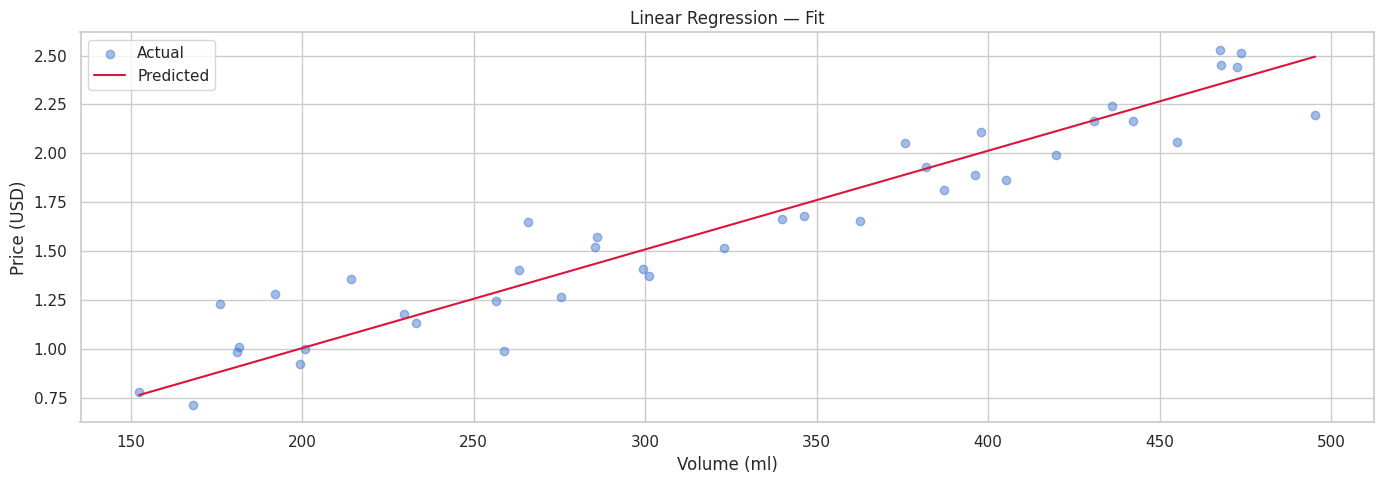

In [ ]:
plt.figure(figsize=(14, 5))

# Scatter plot (Actual values)
plt.scatter(X_test_lr, y_test_lr, alpha=0.5, label='Actual')

# Regression line (Predicted values)
X_sorted = X_test_lr.sort_values('volume_ml')
plt.plot(
    X_sorted,
    lr_model.predict(X_sorted),
    color='crimson',
    label='Predicted'
)

plt.xlabel('Volume (ml)')
plt.ylabel('Price (USD)')
plt.title('Linear Regression — Fit')
plt.legend()

plt.tight_layout()
plt.show()

---

## Section 2 — Classification Dataset: Selecto Wella Lala? (I'm funny, please laugh)


In this classification task, we imagine a scenario where an automated vision and sensor system on a production or retail line must determine whether a given soda can is a **Selecto can (1)** or **not (0)**. The system has to infer the identity from measurable physical and sensory characteristics because it can't read the label directly.

### Features

Each row in the dataset represents one scanned soda can. The features are:

- `volume_ml` — volume of the can in milliliters. Selecto's standard can is 33cl (330 ml).
- `liquid_color` — color category of the liquid inside: dark_brown, amber, golden, clear, or red. Selecto has a characteristic dark caramel-brown color.
- `carbonation_level` — CO2 level in volumes (measure of fizziness). Selecto is moderately to highly carbonated.
- `brix_sugar` — sugar concentration in degrees Brix. Selecto is notably sweet.
- `ph_level` — acidity of the liquid. Most sodas are acidic (pH 2.5 to 4.5).
- `can_height_mm` — physical height of the can in millimeters.
- `can_diameter_mm` — diameter of the can in millimeters.
- `label_primary_color` — dominant color on the can label: red_white, blue, green, orange, or silver_black. Selecto's label is predominantly red and white.
- `has_arabic_script` — whether Arabic text is present on the label (1 = yes, 0 = no). Selecto cans sold in Algeria always carry Arabic script.
- `hamoud_logo_detected` — whether the Hamoud Boualem star logo is detected on the can (1 = yes, 0 = no).

**Target:** `is_selecto` — 1 if the can is a Selecto can, 0 if it belongs to another brand.

You can ignore this next cell, it's just Python code that generates a synthetic dataset, irrelevant for our purposes today x)

In [ ]:
np.random.seed(0)
N = 1200  # Total cans scanned

# --- Selecto cans (600 samples) ---
n_selecto = 600

s_volume          = np.random.choice([330], n_selecto)  # Always 33cl
s_liquid_color    = np.random.choice(['dark_brown', 'amber'], n_selecto, p=[0.88, 0.12])
s_carbonation     = np.random.normal(4.2, 0.25, n_selecto)   # Moderately high
s_brix            = np.random.normal(11.5, 0.6, n_selecto)   # Sweet
s_ph              = np.random.normal(3.1, 0.15, n_selecto)   # Acidic
s_height          = np.random.normal(115.2, 0.8, n_selecto)  # Standard 33cl can
s_diameter        = np.random.normal(66.0, 0.5, n_selecto)
s_label_color     = np.random.choice(['red_white', 'silver_black'], n_selecto, p=[0.92, 0.08])
s_arabic          = np.random.choice([1, 0], n_selecto, p=[0.97, 0.03])  # Almost always Arabic
s_hamoud_logo     = np.random.choice([1, 0], n_selecto, p=[0.95, 0.05])  # Almost always logo

# --- Other brand cans (600 samples) ---
n_other = 600

o_volume          = np.random.choice([250, 330, 355, 500], n_other, p=[0.15, 0.40, 0.25, 0.20])
o_liquid_color    = np.random.choice(['dark_brown', 'amber', 'golden', 'clear', 'red'], n_other,
                                     p=[0.30, 0.15, 0.25, 0.20, 0.10])
o_carbonation     = np.random.normal(3.7, 0.5, n_other)
o_brix            = np.random.normal(10.2, 1.2, n_other)
o_ph              = np.random.normal(3.4, 0.3, n_other)
o_height          = np.random.normal(111.0, 5.0, n_other)
o_diameter        = np.random.normal(66.2, 1.2, n_other)
o_label_color     = np.random.choice(['red_white', 'blue', 'green', 'orange', 'silver_black'],
                                     n_other, p=[0.20, 0.25, 0.20, 0.20, 0.15])
o_arabic          = np.random.choice([1, 0], n_other, p=[0.20, 0.80])  # Few have Arabic
o_hamoud_logo     = np.random.choice([1, 0], n_other, p=[0.02, 0.98])  # Almost never logo

# --- Combine into one DataFrame ---
df_cans = pd.DataFrame({
    'volume_ml':           np.concatenate([s_volume, o_volume]),
    'liquid_color':        np.concatenate([s_liquid_color, o_liquid_color]),
    'carbonation_level':   np.concatenate([s_carbonation, o_carbonation]).round(2),
    'brix_sugar':          np.concatenate([s_brix, o_brix]).round(2),
    'ph_level':            np.concatenate([s_ph, o_ph]).round(2),
    'can_height_mm':       np.concatenate([s_height, o_height]).round(1),
    'can_diameter_mm':     np.concatenate([s_diameter, o_diameter]).round(1),
    'label_primary_color': np.concatenate([s_label_color, o_label_color]),
    'has_arabic_script':   np.concatenate([s_arabic, o_arabic]),
    'hamoud_logo_detected':np.concatenate([s_hamoud_logo, o_hamoud_logo]),
    'is_selecto':          np.concatenate([np.ones(n_selecto, dtype=int),
                                           np.zeros(n_other,   dtype=int)])
})

# Shuffle the dataset
df_cans = df_cans.sample(frac=1, random_state=42).reset_index(drop=True)

print(f'Dataset shape: {df_cans.shape}')
print(f'Selecto cans : {df_cans["is_selecto"].sum()} ({df_cans["is_selecto"].mean():.1%})')
df_cans.head(10)

Dataset shape: (1200, 11)
Selecto cans : 600 (50.0%)


,volume_ml,liquid_color,carbonation_level,brix_sugar,ph_level,can_height_mm,can_diameter_mm,label_primary_color,has_arabic_script,hamoud_logo_detected,is_selecto
0,500,golden,4.46,11.24,3.60,118.9,67.1,blue,0,0,0
1,355,clear,3.76,9.33,3.50,116.3,64.1,orange,0,0,0
2,330,dark_brown,4.19,12.36,3.10,114.3,66.2,red_white,1,1,1
3,330,dark_brown,4.10,11.43,3.33,115.3,65.5,red_white,1,1,1
4,330,dark_brown,4.27,12.29,3.14,115.7,66.5,red_white,1,1,1
5,355,amber,4.21,10.87,3.43,108.4,68.1,silver_black,0,0,0
6,330,dark_brown,3.86,12.38,2.98,115.9,65.5,red_white,1,1,1
7,330,dark_brown,3.61,7.73,3.33,104.8,65.0,green,0,0,0
8,330,dark_brown,4.04,11.34,3.11,116.4,66.7,red_white,1,1,1
9,250,dark_brown,3.82,11.14,3.01,110.9,66.0,blue,0,0,0


### Exploratory Data Analysis

Before modeling, we explore the data visually to understand how Selecto cans differ from other brands across key features.

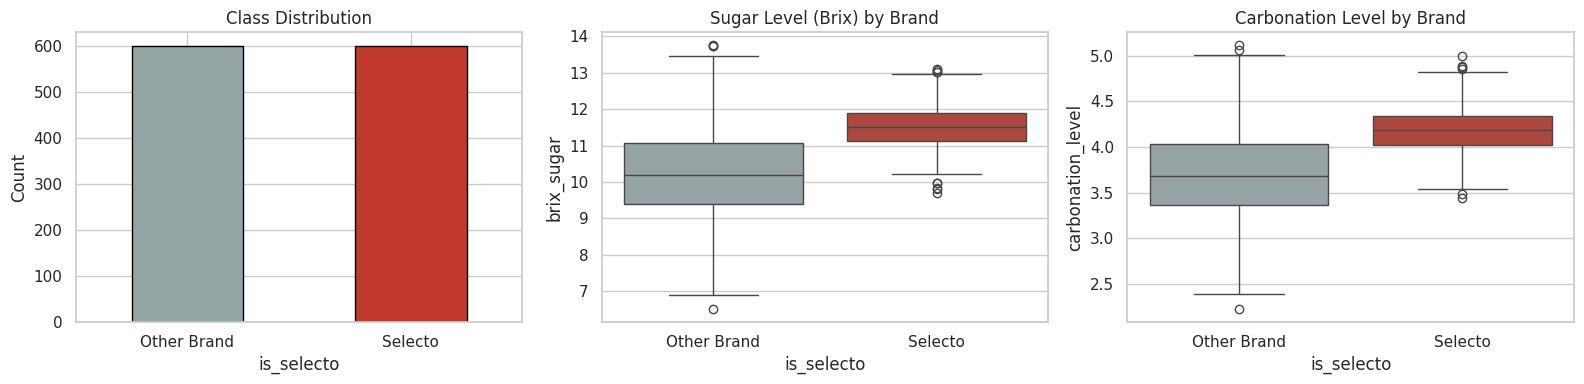

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Class distribution
df_cans['is_selecto'].value_counts().rename({0: 'Other Brand', 1: 'Selecto'}).plot(
    kind='bar', ax=axes[0], color=['#95a5a6', '#c0392b'], edgecolor='black'
)
axes[0].set_title('Class Distribution')
axes[0].set_xticklabels(['Other Brand', 'Selecto'], rotation=0)
axes[0].set_ylabel('Count')

# Brix sugar by class
sns.boxplot(data=df_cans, x='is_selecto', y='brix_sugar', ax=axes[1],
            palette=['#95a5a6', '#c0392b'])
axes[1].set_xticklabels(['Other Brand', 'Selecto'])
axes[1].set_title('Sugar Level (Brix) by Brand')

# Carbonation by class
sns.boxplot(data=df_cans, x='is_selecto', y='carbonation_level', ax=axes[2],
            palette=['#95a5a6', '#c0392b'])
axes[2].set_xticklabels(['Other Brand', 'Selecto'])
axes[2].set_title('Carbonation Level by Brand')

plt.tight_layout()
plt.show()

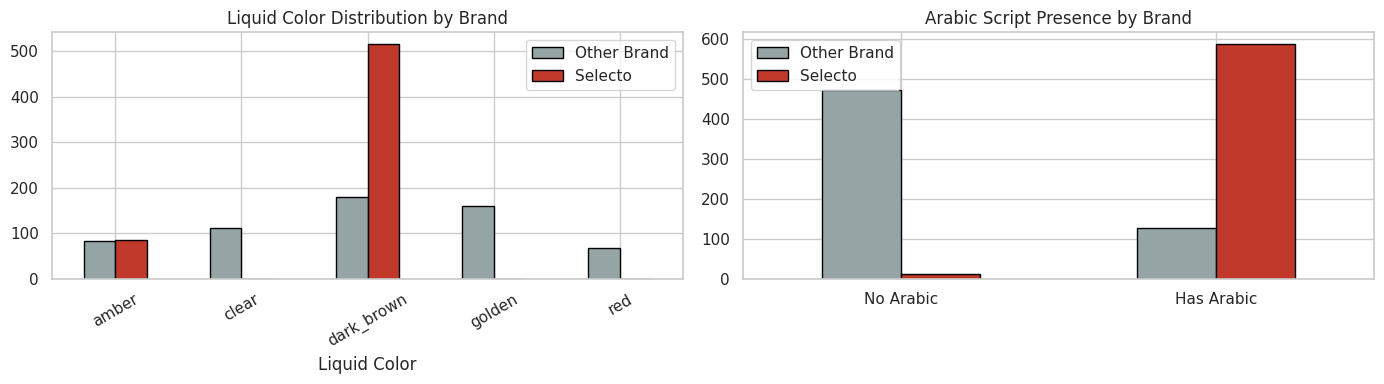

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Liquid color breakdown by class
color_counts = df_cans.groupby(['liquid_color', 'is_selecto']).size().unstack(fill_value=0)
color_counts.columns = ['Other Brand', 'Selecto']
color_counts.plot(kind='bar', ax=axes[0], color=['#95a5a6', '#c0392b'], edgecolor='black')
axes[0].set_title('Liquid Color Distribution by Brand')
axes[0].set_xlabel('Liquid Color')
axes[0].tick_params(axis='x', rotation=30)

# Arabic script presence
arabic_counts = df_cans.groupby(['has_arabic_script', 'is_selecto']).size().unstack(fill_value=0)
arabic_counts.columns = ['Other Brand', 'Selecto']
arabic_counts.index = ['No Arabic', 'Has Arabic']
arabic_counts.plot(kind='bar', ax=axes[1], color=['#95a5a6', '#c0392b'], edgecolor='black')
axes[1].set_title('Arabic Script Presence by Brand')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

### Preprocessing for Classification

Before feeding data into any classifier we need to:

1. Encode categorical columns (`liquid_color`, `label_primary_color`) into numeric form using a label encoder
2. Scale numeric features so that no single feature dominates due to its range (required for Logistic Regression)
3. Split data into training and test sets with stratification to preserve class balance

In [ ]:
# Step 1 — Encode categorical features
df_encoded = df_cans.copy()

le_liq   = LabelEncoder()
le_label = LabelEncoder()

df_encoded['liquid_color']        = le_liq.fit_transform(df_encoded['liquid_color'])
df_encoded['label_primary_color'] = le_label.fit_transform(df_encoded['label_primary_color'])

print('Liquid color mapping:')
print(dict(zip(le_liq.classes_, le_liq.transform(le_liq.classes_))))
print('\nLabel color mapping:')
print(dict(zip(le_label.classes_, le_label.transform(le_label.classes_))))

Liquid color mapping:
{'amber': np.int64(0), 'clear': np.int64(1), 'dark_brown': np.int64(2), 'golden': np.int64(3), 'red': np.int64(4)}

Label color mapping:
{'blue': np.int64(0), 'green': np.int64(1), 'orange': np.int64(2), 'red_white': np.int64(3), 'silver_black': np.int64(4)}


In [ ]:
# Step 2 — Split features and target
feature_cols = [
    'volume_ml', 'liquid_color', 'carbonation_level', 'brix_sugar',
    'ph_level', 'can_height_mm', 'can_diameter_mm',
    'label_primary_color', 'has_arabic_script', 'hamoud_logo_detected'
]

X_cls = df_encoded[feature_cols]
y_cls = df_encoded['is_selecto']

X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
    X_cls, y_cls, test_size=0.2, random_state=42, stratify=y_cls
)

# Step 3 — Scale numeric features (fit only on training set to avoid data leakage!)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_cls)
X_test_scaled  = scaler.transform(X_test_cls)

print(f'Training set : {X_train_scaled.shape}')
print(f'Test set     : {X_test_scaled.shape}')
print(f'Selecto rate in train: {y_train_cls.mean():.1%} | in test: {y_test_cls.mean():.1%}')

Training set : (960, 10)
Test set     : (240, 10)
Selecto rate in train: 50.0% | in test: 50.0%


---

## Section 3 — Logistic Regression

### What Is Logistic Regression?

Logistic regression is a **classification** algorithm (I know, misleading name :p). It estimates the probability that an input belongs to a given class by applying a certain function (called the sigmoid function) to a linear combination of the features (so basically a linear model, like the one we saw in linear regression.) The output is a value between 0 and 1, which is then thresholded (typically at 0.5) to produce a class label.

**When to use it:** When you need an interpretable and easy-to-use classifier for binary or multiclass problems. It works best when the decision boundary is approximately linear.

In [ ]:
log_reg = LogisticRegression(max_iter=500, random_state=42)
log_reg.fit(X_train_scaled, y_train_cls)

y_pred_log = log_reg.predict(X_test_scaled)

print('Logistic Regression — Classification Report')
print('=' * 50)
print(classification_report(y_test_cls, y_pred_log, target_names=['Other Brand', 'Selecto']))

Logistic Regression — Classification Report
              precision    recall  f1-score   support

 Other Brand       0.98      0.99      0.98       120
     Selecto       0.99      0.97      0.98       120

    accuracy                           0.98       240
   macro avg       0.98      0.98      0.98       240
weighted avg       0.98      0.98      0.98       240



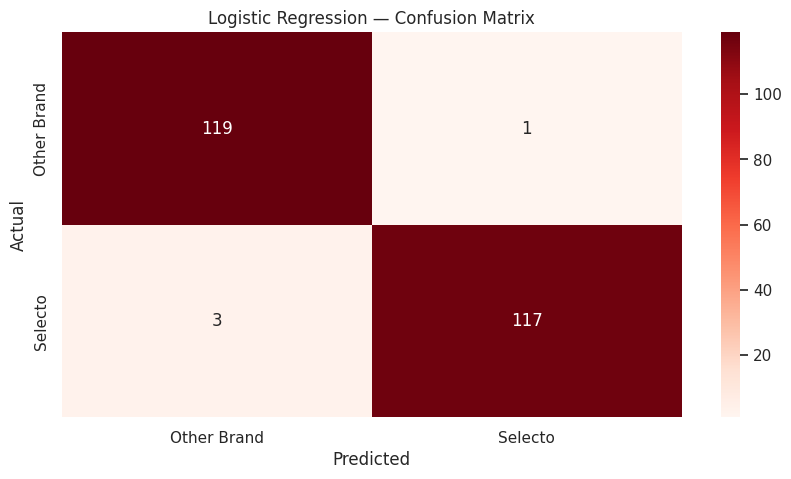

In [ ]:
# Confusion matrix
cm_log = confusion_matrix(y_test_cls, y_pred_log)
sns.heatmap(cm_log, annot=True, fmt='d', cmap='Reds',
            xticklabels=['Other Brand', 'Selecto'],
            yticklabels=['Other Brand', 'Selecto'])
plt.title('Logistic Regression — Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

---

## Section 4 — Decision Tree

### What Is a Decision Tree?

A decision tree partitions the data by learning a set of rules (e.g., "Is seal pressure > 3.2?"). At each internal node of the tree, the algorithm selects the feature and threshold that best separates the classes, measured by criteria such as Gini impurity or information gain. The final leaf nodes hold the predicted class.

**When to use it:** When interpretability is a priority and you want to be able to explain every prediction as a series of simple if-else conditions. It handles mixed data types well and requires minimal preprocessing.

In [ ]:
dt_model = DecisionTreeClassifier(max_depth=5, random_state=42)
dt_model.fit(X_train_cls, y_train_cls)     # Trees do not require scaling!

y_pred_dt = dt_model.predict(X_test_cls)

print('Decision Tree — Classification Report')
print('=' * 50)
print(classification_report(y_test_cls, y_pred_dt, target_names=['Other Brand', 'Selecto']))

Decision Tree — Classification Report
              precision    recall  f1-score   support

 Other Brand       1.00      0.98      0.99       120
     Selecto       0.98      1.00      0.99       120

    accuracy                           0.99       240
   macro avg       0.99      0.99      0.99       240
weighted avg       0.99      0.99      0.99       240



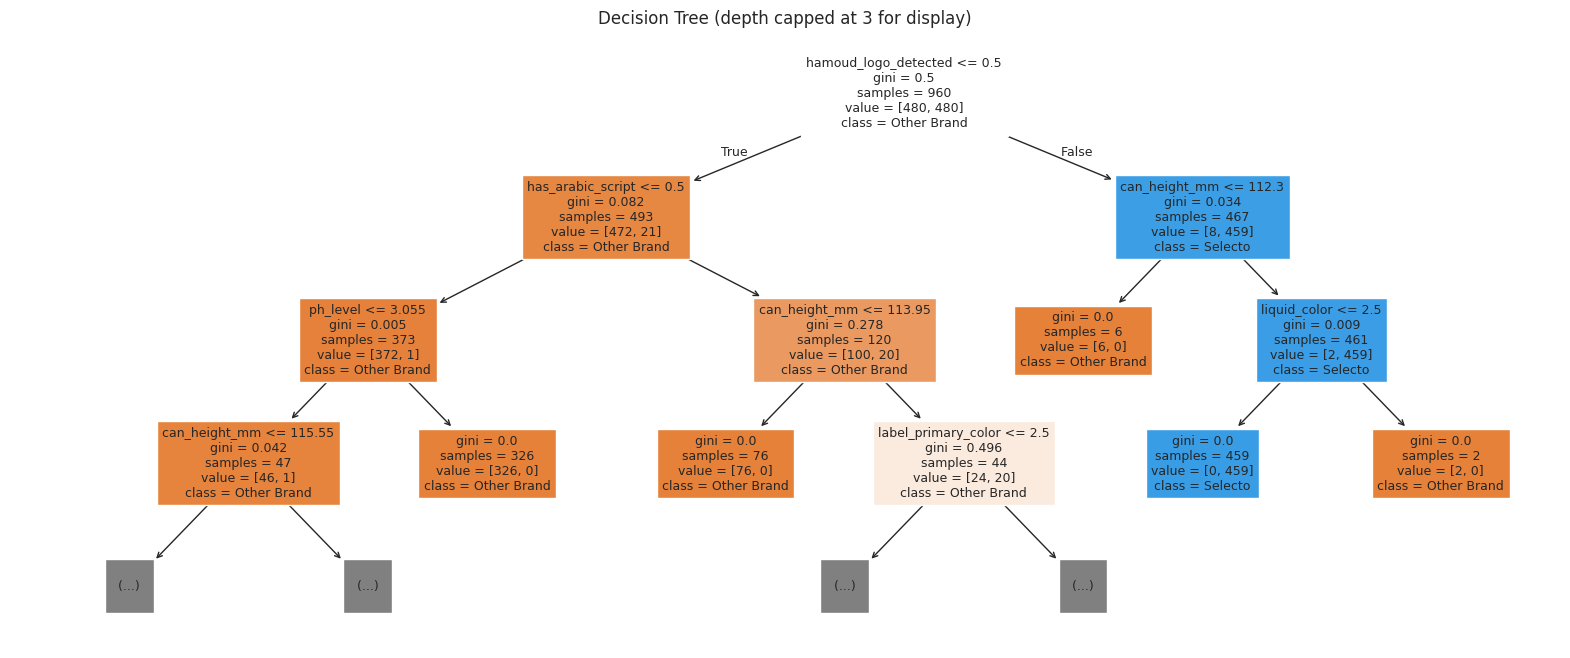

In [ ]:
# Visualize the tree (machi complet, it's quite big)
plt.figure(figsize=(20, 8))
plot_tree(
    dt_model,
    feature_names=feature_cols,
    class_names=['Other Brand', 'Selecto'],
    filled=True,
    max_depth=3,
    fontsize=9
)
plt.title('Decision Tree (depth capped at 3 for display)')
plt.show()

---

## Section 5 — Random Forest

### What Is a Random Forest?

A random forest is an **ensemble** method that builds many decision trees on random subsets of the training data and random subsets of features, then aggregates their predictions by majority vote. This reduces overfitting and variance compared to a single decision tree.

**When to use it:** When you need high predictive accuracy and can tolerate lower interpretability than a single tree. Random forests are robust to outliers.

In [ ]:
rf_model = RandomForestClassifier(n_estimators=100, max_depth=8, random_state=42)
rf_model.fit(X_train_cls, y_train_cls)

y_pred_rf = rf_model.predict(X_test_cls)

print('Random Forest — Classification Report')
print('=' * 50)
print(classification_report(y_test_cls, y_pred_rf, target_names=['Other Brand', 'Selecto']))

Random Forest — Classification Report
              precision    recall  f1-score   support

 Other Brand       1.00      1.00      1.00       120
     Selecto       1.00      1.00      1.00       120

    accuracy                           1.00       240
   macro avg       1.00      1.00      1.00       240
weighted avg       1.00      1.00      1.00       240



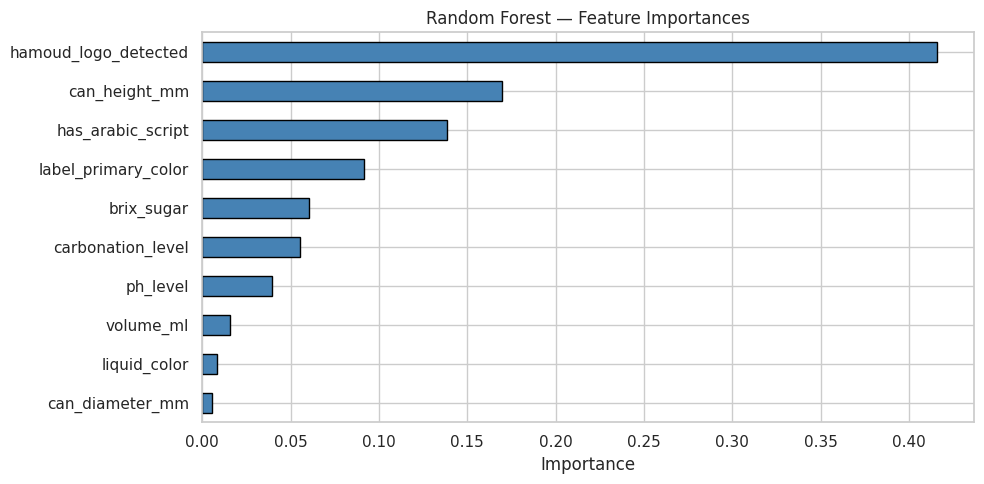

In [ ]:
# Feature importance
importances = pd.Series(rf_model.feature_importances_, index=feature_cols).sort_values(ascending=True)

importances.plot(kind='barh', color='steelblue', edgecolor='black')
plt.title('Random Forest — Feature Importances')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

---

## Section 6 — K-Means Clustering on Student Data

### What Is K-Means Clustering?

K-Means is an **unsupervised** algorithm that groups data points into K clusters based on feature similarity. It works by assigning each point to the nearest cluster center and then updating them until convergence.

**When to use it:** When you want to discover natural groupings in your data without predefined labels.

### Dataset

We use the Mall Customers Segmentation Dataset, a popular dataset for customer clustering and market segmentation analysis.

Link to the dataset on Kaggle:
https://www.kaggle.com/datasets/shwetabh123/mall-customers

This dataset contains basic demographic and spending information for customers of a shopping mall.

**Columns we will cluster on:**

- `Age` — Customer age
- `Annual Income (k$)` — Annual income in thousand dollars
- `Spending Score (1-100)` — Score assigned by the mall based on customer spending behavior

In [ ]:
df_mall = pd.read_csv('/content/Mall_Customers.csv')

print(f'Mall dataset shape: {df_mall.shape}')
df_mall.describe()

Mall dataset shape: (200, 5)


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


### Preprocessing for Clustering

K-Means is sensitive to feature scale because it relies on Euclidean distance. We must standardize all features before clustering. We also check for missing values.

In [ ]:
# Step 1 — Check for missing values
print('Missing values per column:')
print(df_mall.isnull().sum())

Missing values per column:
CustomerID                0
Genre                     0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


In [ ]:
# Step 2 — Select features for clustering
cluster_features = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
X_cluster = df_mall[cluster_features].copy()

# Step 3 — Standardize
scaler_km = StandardScaler()
X_cluster_scaled = scaler_km.fit_transform(X_cluster)

print('Feature means after scaling (should be ~0):')

print(X_cluster_scaled.mean(axis=0).round(4))


Feature means after scaling (should be ~0):
[-0. -0. -0.]


### Training the Final K-Means Model

Based on the elbow and silhouette plots, we select K = 3 clusters. Adjust this value if your own analysis suggests a different number.

In [ ]:
K = 3

kmeans = KMeans(n_clusters=K, random_state=42, n_init=10)
df_mall['cluster'] = kmeans.fit_predict(X_cluster_scaled)

print(f'Silhouette Score (K={K}): {silhouette_score(X_cluster_scaled, df_mall["cluster"]):.4f}')
print('\nCluster sizes:')
print(df_mall['cluster'].value_counts().sort_index())

Silhouette Score (K=3): 0.3578

Cluster sizes:
cluster
0    68
1    41
2    91
Name: count, dtype: int64


### Cluster Profiles

We examine the mean of each feature within each cluster to understand what distinguishes the groups.

In [ ]:
cluster_profile = df_mall.groupby('cluster')[cluster_features].mean().round(2)
print('Mean feature values by cluster:')
cluster_profile

Mean feature values by cluster:


,Age,Annual Income (k$),Spending Score (1-100)
cluster,,,
0,25.84,42.75,53.65
1,32.85,87.34,79.98
2,51.27,61.80,34.21


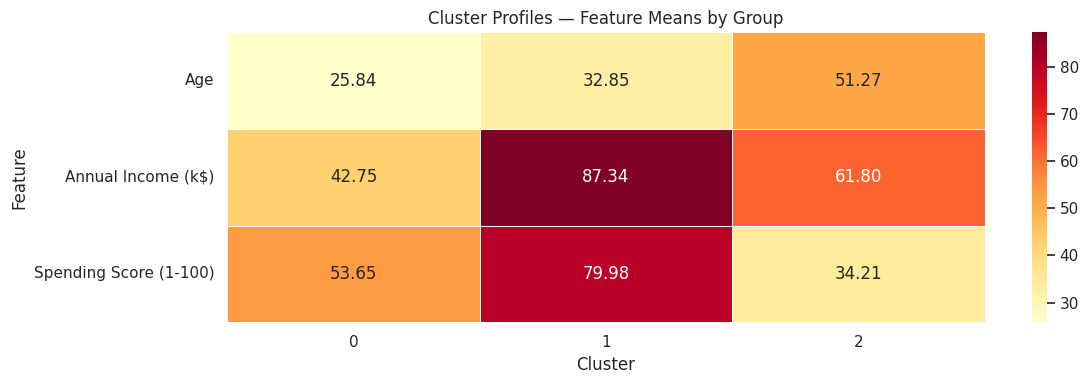

In [ ]:
# Visualize cluster profiles as a heatmap
plt.figure(figsize=(12, 4))
sns.heatmap(
    cluster_profile.T,
    annot=True, fmt='.2f', cmap='YlOrRd',
    linewidths=0.5, linecolor='white'
)
plt.title('Cluster Profiles — Feature Means by Group')
plt.ylabel('Feature')
plt.xlabel('Cluster')
plt.tight_layout()
plt.show()

### Scatter plot

We visualise the clusters to understand and manually evaluate the separation between clusters.

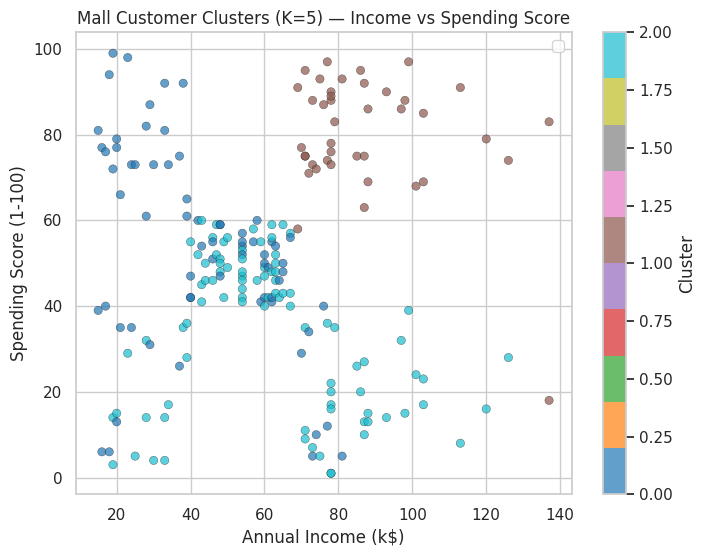

In [ ]:
# 2D scatter — Annual Income vs Spending Score, colored by cluster

x_col = 'Annual Income (k$)'
y_col = 'Spending Score (1-100)'

plt.figure(figsize=(8, 6))

# Data points
scatter = plt.scatter(
    df_mall[x_col],
    df_mall[y_col],
    c=df_mall['cluster'],
    cmap='tab10',
    alpha=0.7,
    edgecolors='k',
    linewidths=0.3
)


plt.xlabel(x_col)
plt.ylabel(y_col)
plt.title('Mall Customer Clusters (K=5) — Income vs Spending Score')
plt.legend()
plt.colorbar(scatter, label='Cluster')
plt.show()